
# Machine Learning Assignment 2
## Student Dropout and Academic Success Prediction

### 1. Project Objective
The objective of this project is to implement and compare five machine learning classification algorithms to predict student academic outcomes.

### 2. Classification Models
1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbors (KNN)
4. Gaussian Naive Bayes
5. Support Vector Machine (SVM)

### 3. Evaluation Metrics
The models will be evaluated using Accuracy, AUC Score, Precision, Recall, F1-score, and Matthews Correlation Coefficient (MCC).

### 4. Dataset
The Student Dropout and Academic Success dataset contains student demographic, academic, and socioeconomic information. The target variable has three classes: Dropout, Enrolled, and Graduate.

### 5. Project Workflow
Dataset inspection, data preprocessing, exploratory data analysis, model training, evaluation, model comparison, and deployment preparation.



## Step 1: Import Required Libraries

We import the Python libraries needed for data handling, numerical calculations, and visualization. These libraries will support dataset inspection and exploratory data analysis before model development.



In [1]:

# Import pandas for loading and manipulating tabular data
import pandas as pd

# Import NumPy for numerical computations
import numpy as np

# Import Matplotlib for creating plots and charts
import matplotlib.pyplot as plt

# Import Seaborn for statistical data visualizations
import seaborn as sns

# Display a confirmation message after successful imports
print("All required data analysis libraries imported successfully.")



All required data analysis libraries imported successfully.



## Step 2: Load the Dataset

The downloaded Student Dropout and Academic Success dataset is loaded into a Pandas DataFrame. The file uses semicolons as separators, so we explicitly specify the delimiter when reading the CSV file. We then inspect the dataset dimensions and preview the first five records to verify successful loading.


In [2]:

# Load the CSV file, using semicolon as the field separator
df = pd.read_csv("data.csv", sep=";")

# Print a confirmation that the dataset was loaded
print("Dataset loaded successfully.")

# Display the total number of records and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display the first five records to inspect the dataset
display(df.head())


Dataset loaded successfully.
Number of rows: 4424
Number of columns: 37


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate



## Step 3: Inspect Dataset Features

In this step, we examine the names of all columns in the dataset. This helps us identify the input features and locate the target variable that the classification models will predict.


In [3]:

# Display all column names in the dataset
print("Column names:")
for column in df.columns:
    print(column)

# Verify that the target column exists
print("\nTarget column present:", "Target" in df.columns)


Column names:
Marital status
Application mode
Application order
Course
Daytime/evening attendance	
Previous qualification
Previous qualification (grade)
Nacionality
Mother's qualification
Father's qualification
Mother's occupation
Father's occupation
Admission grade
Displaced
Educational special needs
Debtor
Tuition fees up to date
Gender
Scholarship holder
Age at enrollment
International
Curricular units 1st sem (credited)
Curricular units 1st sem (enrolled)
Curricular units 1st sem (evaluations)
Curricular units 1st sem (approved)
Curricular units 1st sem (grade)
Curricular units 1st sem (without evaluations)
Curricular units 2nd sem (credited)
Curricular units 2nd sem (enrolled)
Curricular units 2nd sem (evaluations)
Curricular units 2nd sem (approved)
Curricular units 2nd sem (grade)
Curricular units 2nd sem (without evaluations)
Unemployment rate
Inflation rate
GDP
Target

Target column present: True



## Step 4: Examine Data Types

We inspect the data type of each column to understand the dataset's structure. This helps identify numerical and categorical variables and determine whether any preprocessing is required before model training.


In [4]:

# Display the data type of every column
print("Data types of dataset columns:")
display(df.dtypes.to_frame(name="Data Type"))

# Display a concise summary of the DataFrame
print("\nDataset information:")
df.info()


Data types of dataset columns:


,Data Type
Marital status,int64
Application mode,int64
Application order,int64
Course,int64
Daytime/evening attendance\t,int64
Previous qualification,int64
Previous qualification (grade),float64
Nacionality,int64
Mother's qualification,int64
Father's qualification,int64



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualificat


## Step 5: Check for Missing Values

Missing values can affect machine learning model training and evaluation. We calculate the number of missing values in each column and the total number of missing values in the dataset to determine whether any missing-value treatment is necessary.


In [5]:

# Count missing values in each column
missing_by_column = df.isnull().sum()

# Display only columns that contain missing values
print("Columns containing missing values:")
display(missing_by_column[missing_by_column > 0])

# Calculate the total number of missing values
total_missing = df.isnull().sum().sum()
print("Total missing values:", total_missing)


Columns containing missing values:


Series([], dtype: int64)

Total missing values: 0



## Step 6: Check for Duplicate Records

Duplicate records can affect the reliability of machine learning evaluation. In this step, we identify the number of completely duplicated rows in the dataset before deciding whether any records need to be removed.


In [6]:

# Count the number of rows that are exact duplicates
duplicate_count = df.duplicated().sum()

# Display the duplicate count
print("Number of duplicate records:", duplicate_count)

# Display the dataset dimensions before any duplicate removal
print("Dataset shape before duplicate handling:", df.shape)


Number of duplicate records: 0
Dataset shape before duplicate handling: (4424, 37)



## Step 7: Analyze the Target Variable

The target variable represents the student outcome that the classification models will predict. We examine the distinct target classes and their frequencies to verify that the dataset contains the three expected outcomes: Dropout, Enrolled, and Graduate.


In [7]:

# Display the number of records belonging to each target class
print("Target class counts:")
display(df["Target"].value_counts().to_frame(name="Count"))

# Display the number of distinct target classes
print("\nNumber of target classes:", df["Target"].nunique())

# Print the names of the target classes
print("Target class labels:", df["Target"].unique().tolist())


Target class counts:


,Count
Graduate,2209
Dropout,1421
Enrolled,794



Number of target classes: 3
Target class labels: ['Dropout', 'Graduate', 'Enrolled']



## Step 8: Visualize Target Class Distribution

A bar chart is used to visualize the number of records in each student outcome category. This helps us assess class imbalance and understand whether some outcomes occur more frequently than others.


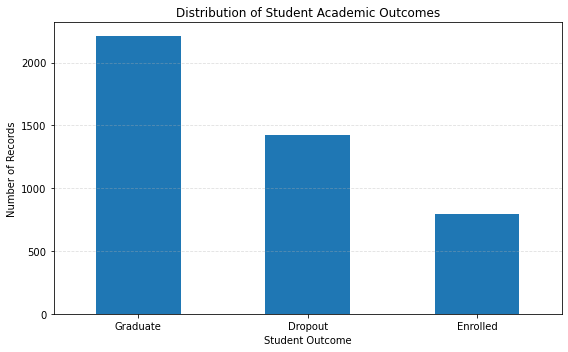

In [8]:

# Count records in each target category
target_counts = df["Target"].value_counts()

# Create a bar chart showing the target class distribution
plt.figure(figsize=(8, 5))
target_counts.plot(kind="bar")

# Add descriptive chart labels and a title
plt.title("Distribution of Student Academic Outcomes")
plt.xlabel("Student Outcome")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)

# Add gridlines to make the counts easier to compare
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Adjust spacing and display the chart
plt.tight_layout()
plt.show()



## Step 9: Separate Input Features and Target Variable

The input features contain the student-related information used for prediction, while the target variable represents the academic outcome. We separate them to prepare the dataset for supervised classification.

The Target column is excluded from the input features to prevent target leakage.


In [9]:

# Separate input features from the target variable
X = df.drop(columns=["Target"])

# Store the target labels separately
y = df["Target"]

# Display the dimensions of the features and target
print("Input feature matrix shape:", X.shape)
print("Target variable shape:", y.shape)

# Confirm that the target column is not included in X
print("Target included in input features:", "Target" in X.columns)


Input feature matrix shape: (4424, 36)
Target variable shape: (4424,)
Target included in input features: False



## Step 10: Generate Descriptive Statistics

We calculate descriptive statistics for the numerical input features, including the mean, standard deviation, minimum, maximum, and quartiles. This helps us understand feature scales and identify potentially unusual values.


In [10]:

# Select numerical input features
numeric_features = X.select_dtypes(include=np.number)

# Generate descriptive statistics for numerical features
summary_stats = numeric_features.describe().T

# Display the statistics table
display(summary_stats)

# Check the number of numerical features
print("Number of numerical features:", numeric_features.shape[1])


,count,mean,std,min,25%,50%,75%,max
Marital status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance\t,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


Number of numerical features: 36



## Step 11: Visualize Selected Feature Distributions

Histograms help us understand how numerical values are distributed across selected features. We visualize a small subset of features to keep the analysis readable while examining differences in scale, spread, and skewness.


/Users/abcd/opt/anaconda3/lib/python3.9/site-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


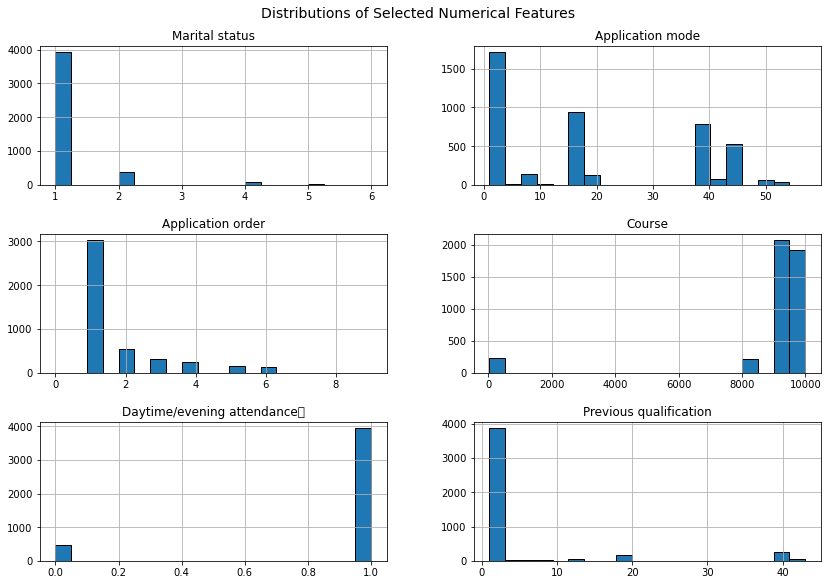

In [11]:

# Select up to six numerical features for visualization
selected_features = numeric_features.columns[:6]

# Create histograms for the selected features
axes = numeric_features[selected_features].hist(
    figsize=(14, 9),
    bins=20,
    edgecolor="black"
)

# Add a descriptive title
plt.suptitle(
    "Distributions of Selected Numerical Features",
    fontsize=14,
    fontfamily="DejaVu Sans"
)

# Adjust subplot spacing without using tight_layout
plt.subplots_adjust(top=0.92, hspace=0.35, wspace=0.25)

# Display the histograms
plt.show()




## Step 12: Analyze Feature Correlations

A correlation matrix summarizes the linear relationships between numerical input features. A heatmap provides a visual overview of positive and negative correlations and helps identify strongly related variables before model training.



# Calculate correlations between numerical input features
correlation_matrix = numeric_features.corr()

# Create a figure for the correlation heatmap
plt.figure(figsize=(16, 12))

# Draw the heatmap without displaying feature labels
# This avoids the missing-font-glyph warning from the labels
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    xticklabels=False,
    yticklabels=False,
    cbar_kws={"label": "Correlation"}
)

# Add a descriptive title
plt.title("Correlation Heatmap of Numerical Input Features", fontsize=14)

# Add axis labels
plt.xlabel("Numerical Features")
plt.ylabel("Numerical Features")

# Adjust the plot spacing
plt.subplots_adjust(left=0.12, bottom=0.12)

# Display the heatmap
plt.show()



## Step 13: Verify the Feature Matrix and Target Variable

Before splitting the data, we verify that the input features and target variable contain the same number of observations. We also confirm that all three target classes are present and that the target column is excluded from the input features.


In [12]:

# Display the dimensions of the input features and target
print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

# Display the unique target classes
print("\nTarget classes:")
print(sorted(y.unique()))

# Confirm that the target is excluded from the input features
print("\nTarget column excluded from X:", "Target" not in X.columns)

# Verify that both datasets contain the same number of observations
print("Matching observation counts:", len(X) == len(y))


Feature matrix shape: (4424, 36)
Target vector shape: (4424,)

Target classes:
['Dropout', 'Enrolled', 'Graduate']

Target column excluded from X: True
Matching observation counts: True



## Step 14: Split the Dataset into Training and Testing Sets

We divide the dataset into training and testing subsets. The training set is used to fit the classification models, while the testing set is reserved for evaluating their performance on unseen observations.

We use an 80:20 split with stratified sampling to preserve the approximate proportions of the three target classes. A fixed random state ensures reproducibility.


In [13]:

# Import the function for splitting the dataset
from sklearn.model_selection import train_test_split

# Create stratified training and testing subsets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the dimensions of the resulting datasets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (3539, 36)
Testing features: (885, 36)
Training target: (3539,)
Testing target: (885,)



## Step 15: Verify Class Distribution After Splitting

We compare the proportions of Dropout, Enrolled, and Graduate in the original dataset, training set, and testing set. This checks whether stratified sampling has maintained a representative distribution of the target classes.


In [14]:

# Calculate class proportions in the original dataset
original_distribution = y.value_counts(normalize=True).sort_index()

# Calculate class proportions in the training set
train_distribution = y_train.value_counts(normalize=True).sort_index()

# Calculate class proportions in the testing set
test_distribution = y_test.value_counts(normalize=True).sort_index()

# Combine the proportions into a comparison table
distribution_comparison = pd.DataFrame({
    "Original Dataset": original_distribution,
    "Training Set": train_distribution,
    "Testing Set": test_distribution
})

# Display the class proportions rounded to four decimal places
display(distribution_comparison.round(4))


,Original Dataset,Training Set,Testing Set
Dropout,0.3212,0.3213,0.3209
Enrolled,0.1795,0.1794,0.1797
Graduate,0.4993,0.4993,0.4994



## Step 16: Standardize the Input Features

Feature scaling is important for Logistic Regression, K-Nearest Neighbors, and Support Vector Machine because these algorithms are sensitive to feature magnitudes.

We use StandardScaler to standardize the input features. The scaler is fitted only on the training set and then applied to the testing set using the same learned parameters. This prevents data leakage from the testing set.


In [15]:

# Import StandardScaler for feature standardization
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Fit the scaler on the training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform the testing data using the training-set parameters
X_test_scaled = scaler.transform(X_test)

# Display the scaled dataset dimensions
print("Scaled training features:", X_train_scaled.shape)
print("Scaled testing features:", X_test_scaled.shape)

# Check the mean and standard deviation of the first scaled feature
print("\nMean of first scaled training feature:",
      round(X_train_scaled[:, 0].mean(), 4))
print("Standard deviation of first scaled training feature:",
      round(X_train_scaled[:, 0].std(), 4))


Scaled training features: (3539, 36)
Scaled testing features: (885, 36)

Mean of first scaled training feature: -0.0
Standard deviation of first scaled training feature: 1.0



## Step 17: Import and Define the Classification Models

We implement the five classification algorithms required by the assignment: Logistic Regression, Decision Tree, K-Nearest Neighbors, Gaussian Naive Bayes, and Support Vector Machine.

All five models will use the same training and testing split. Scale-sensitive models will use standardized features, while Decision Tree and Gaussian Naive Bayes will use the original feature values.


In [16]:

# Import the five required classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Define each model with reproducible settings where applicable
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6, random_state=42
    ),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(
        probability=True, random_state=42
    )
}

# Display the models selected for the experiment
print("Classification models defined:")
for model_name in models:
    print("-", model_name)

print("\nTotal number of models:", len(models))


Classification models defined:
- Logistic Regression
- Decision Tree
- KNN
- Naive Bayes
- Support Vector Machine

Total number of models: 5



## Step 18: Define the Evaluation Metrics

We evaluate each classifier using six metrics: Accuracy, Area Under the ROC Curve (AUC), Precision, Recall, F1-score, and Matthews Correlation Coefficient (MCC).

Since the target contains three classes, we use macro-averaging for Precision, Recall, and F1-score. AUC is calculated using the one-vs-rest (OvR) approach with macro-averaging. MCC provides a summary of classification quality that considers the agreement between actual and predicted labels.


In [17]:

# Import the evaluation metrics required by the assignment
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# Confirm that all evaluation metrics are available
print("All six evaluation metrics imported successfully.")


All six evaluation metrics imported successfully.



## Step 19: Train the Five Classification Models

Each classifier is trained using the same training observations. Logistic Regression, KNN, and SVM use standardized features, while Decision Tree and Gaussian Naive Bayes use the original features.

After training, each model predicts the academic outcomes in the held-out testing set and generates class probabilities for AUC calculation. The models are not trained on the testing data.


In [18]:

# Store predictions and probabilities for subsequent analysis
results = {}
trained_models = {}

# Identify the models that require standardized features
scaled_model_names = {
    "Logistic Regression",
    "KNN",
    "Support Vector Machine"
}

# Train each classifier and evaluate its predictions
for model_name, model in models.items():

    # Select the appropriate training and testing features
    if model_name in scaled_model_names:
        X_tr = X_train_scaled
        X_te = X_test_scaled
    else:
        X_tr = X_train
        X_te = X_test

    # Fit the model using only the training data
    print(f"Training {model_name}...")
    model.fit(X_tr, y_train)

    # Predict class labels and class probabilities
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)

    # Save the fitted model and its predictions
    trained_models[model_name] = model
    results[model_name] = {
        "predictions": y_pred,
        "probabilities": y_prob
    }

    print(f"{model_name} training and prediction completed.")

print("\nAll five models have been trained.")


Training Logistic Regression...
Logistic Regression training and prediction completed.
Training Decision Tree...
Decision Tree training and prediction completed.
Training KNN...
KNN training and prediction completed.
Training Naive Bayes...
Naive Bayes training and prediction completed.
Training Support Vector Machine...
Support Vector Machine training and prediction completed.

All five models have been trained.



## Step 20: Calculate the Evaluation Metrics

We calculate Accuracy, multiclass AUC, macro Precision, macro Recall, macro F1-score, and MCC for each trained classifier.

The same testing set is used for all models to ensure a fair comparison. The multiclass AUC uses one-vs-rest macro averaging, while Precision, Recall, and F1-score use macro averaging so that each class contributes equally to the aggregate score.


In [19]:

# Create a list to collect the evaluation results
metric_rows = []

# Calculate all six metrics for each classifier
for model_name, model_result in results.items():

    # Retrieve predictions and predicted class probabilities
    y_pred = model_result["predictions"]
    y_prob = model_result["probabilities"]

    # Calculate the required evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(
        y_test,
        y_prob,
        labels=model.classes_,
        multi_class="ovr",
        average="macro"
    )

    precision = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    # Store the scores in a structured row
    metric_rows.append({
        "ML Model Name": model_name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    })

# Create a DataFrame containing the evaluation results
metrics_df = pd.DataFrame(metric_rows).set_index("ML Model Name")

# Display the comparison table rounded to four decimal places
print("Performance Comparison of the Five Classification Models")
display(metrics_df.round(4))


Performance Comparison of the Five Classification Models


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
ML Model Name,,,,,,
Logistic Regression,0.7684,0.8779,0.7070,0.6754,0.6826,0.6150
Decision Tree,0.7322,0.8398,0.6706,0.6453,0.6530,0.5549
KNN,0.6734,0.7883,0.5899,0.5722,0.5751,0.4529
Naive Bayes,0.6599,0.7908,0.5669,0.5586,0.5581,0.4303
Support Vector Machine,0.7582,0.8664,0.7051,0.6676,0.6785,0.5986



## Step 21: Analyze Confusion Matrices

A confusion matrix compares the actual student outcomes with the outcomes predicted by a classification model. It shows correct classifications along the diagonal and misclassifications in the off-diagonal cells.

We examine the confusion matrix for each classifier to understand which academic outcomes are predicted correctly and which are confused with other classes.


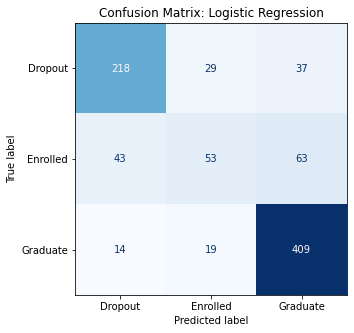

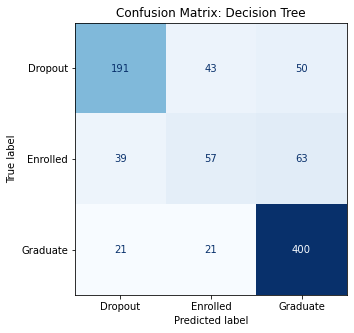

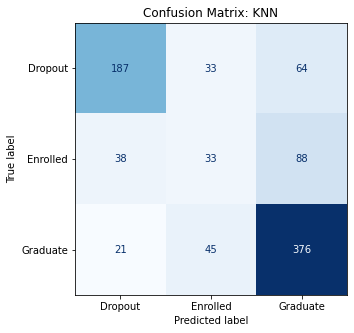

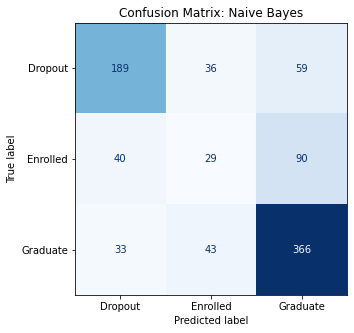

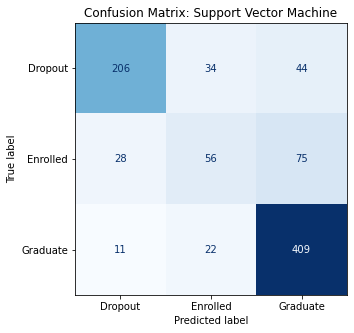

In [20]:

# Import the confusion matrix display utility
from sklearn.metrics import ConfusionMatrixDisplay

# Define the order of the three target classes
class_labels = ["Dropout", "Enrolled", "Graduate"]

# Create a separate confusion matrix for each trained model
for model_name, model_result in results.items():

    # Retrieve the model's predictions
    y_pred = model_result["predictions"]

    # Calculate the confusion matrix using a consistent class order
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    # Plot the confusion matrix
    fig, ax = plt.subplots(figsize=(6, 5))

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_labels
    )

    display_matrix.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    # Add a title and display the plot
    ax.set_title(f"Confusion Matrix: {model_name}")
    plt.show()



## Step 22: Generate Classification Reports

A classification report provides class-wise Precision, Recall, and F1-score, along with the number of test observations belonging to each class. It also includes macro and weighted averages, allowing us to assess performance across individual student outcomes.


In [21]:

# Generate a classification report for each trained model
for model_name, model_result in results.items():

    # Retrieve the predicted labels
    y_pred = model_result["predictions"]

    # Calculate the class-wise classification report
    report = classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        target_names=class_labels,
        zero_division=0
    )

    # Display the report for the current model
    print("=" * 70)
    print(f"Classification Report: {model_name}")
    print("=" * 70)
    print(report)


Classification Report: Logistic Regression
              precision    recall  f1-score   support

     Dropout       0.79      0.77      0.78       284
    Enrolled       0.52      0.33      0.41       159
    Graduate       0.80      0.93      0.86       442

    accuracy                           0.77       885
   macro avg       0.71      0.68      0.68       885
weighted avg       0.75      0.77      0.75       885

Classification Report: Decision Tree
              precision    recall  f1-score   support

     Dropout       0.76      0.67      0.71       284
    Enrolled       0.47      0.36      0.41       159
    Graduate       0.78      0.90      0.84       442

    accuracy                           0.73       885
   macro avg       0.67      0.65      0.65       885
weighted avg       0.72      0.73      0.72       885

Classification Report: KNN
              precision    recall  f1-score   support

     Dropout       0.76      0.66      0.71       284
    Enrolled       0.3


## Step 23: Compare and Rank Model Performance

We compare the five classifiers using the previously calculated evaluation metrics. Accuracy, AUC, Precision, Recall, F1-score, and MCC provide complementary perspectives on classification quality.

We use macro F1-score as the primary ranking metric because it gives equal importance to each target class. The other metrics are used to provide additional context when selecting the overall best-performing model.


In [22]:

# Sort the models by macro F1-score in descending order
ranked_models = metrics_df.sort_values(
    by="F1 Score",
    ascending=False
)

# Display the ranked comparison table
print("Models ranked by macro F1-score:")
display(ranked_models.round(4))

# Identify the highest-ranked model
best_model_name = ranked_models.index[0]

# Display the winner and its evaluation scores
print("\nBest model by macro F1-score:", best_model_name)
display(ranked_models.iloc[[0]].round(4))


Models ranked by macro F1-score:


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
ML Model Name,,,,,,
Logistic Regression,0.7684,0.8779,0.7070,0.6754,0.6826,0.6150
Support Vector Machine,0.7582,0.8664,0.7051,0.6676,0.6785,0.5986
Decision Tree,0.7322,0.8398,0.6706,0.6453,0.6530,0.5549
KNN,0.6734,0.7883,0.5899,0.5722,0.5751,0.4529
Naive Bayes,0.6599,0.7908,0.5669,0.5586,0.5581,0.4303



Best model by macro F1-score: Logistic Regression


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
ML Model Name,,,,,,
Logistic Regression,0.7684,0.8779,0.707,0.6754,0.6826,0.615



## Step 24: Interpret the Model Comparison Results

The evaluation results are used to identify the relative strengths and limitations of the five classifiers. The analysis considers overall predictive performance, class-wise performance, and the balance between Precision and Recall.

The final observations and selection of the best model will be based on the measured results rather than assumptions about which algorithm should perform best.


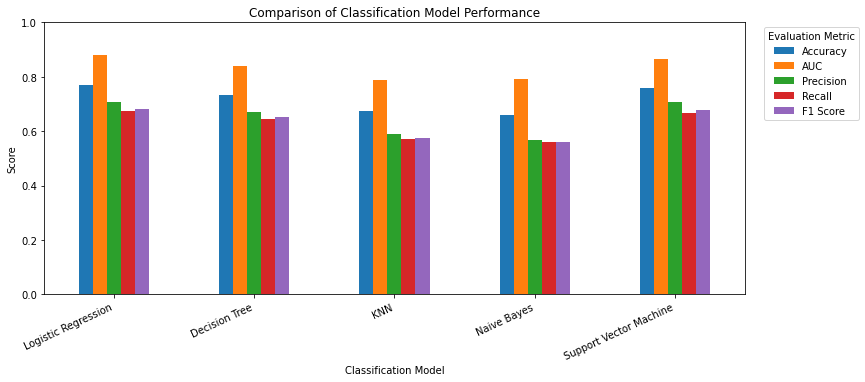

In [23]:

# Select the metrics to compare visually
metrics_to_plot = [
    "Accuracy", "AUC", "Precision", "Recall", "F1 Score"
]

# Create a grouped bar chart of the evaluation metrics
ax = metrics_df[metrics_to_plot].plot(
    kind="bar",
    figsize=(14, 6)
)

# Add descriptive labels and a title
ax.set_title("Comparison of Classification Model Performance")
ax.set_xlabel("Classification Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)

# Improve readability of the chart
plt.xticks(rotation=25, ha="right")
plt.legend(title="Evaluation Metric", bbox_to_anchor=(1.02, 1))
plt.subplots_adjust(bottom=0.25, right=0.82)

# Display the chart
plt.show()



## Step 25: Save the Trained Classification Models

The five trained classifiers are saved as reusable model files using Joblib. Saving the fitted models allows the Streamlit application to load them and evaluate uploaded test data without retraining.


In [24]:

# Import Joblib for saving trained machine learning models
import joblib
import os

# Create a directory for storing model files
os.makedirs("model", exist_ok=True)

# Save each fitted classifier to the model directory
for model_name, model in trained_models.items():

    # Create a filename from the model name
    filename = model_name.lower().replace(" ", "_") + ".joblib"
    filepath = os.path.join("model", filename)

    # Save the fitted model
    joblib.dump(model, filepath)

    print(f"Saved {model_name} to {filepath}")

print("\nAll five trained models have been saved.")


Saved Logistic Regression to model/logistic_regression.joblib
Saved Decision Tree to model/decision_tree.joblib
Saved KNN to model/knn.joblib
Saved Naive Bayes to model/naive_bayes.joblib
Saved Support Vector Machine to model/support_vector_machine.joblib

All five trained models have been saved.



## Step 26: Save the Preprocessing Artifacts

The fitted StandardScaler and the target class labels are saved for later use. The scaler ensures that the Streamlit application applies the same feature transformation used during training, while the class labels help maintain consistent target-class interpretation.


In [25]:

# Save the fitted scaler used by Logistic Regression, KNN, and SVM
joblib.dump(scaler, "model/scaler.joblib")

# Save the target class labels in their original text form
class_labels = sorted(y.unique().tolist())
joblib.dump(class_labels, "model/class_labels.joblib")

# Confirm that both preprocessing artifacts were saved
print("Scaler saved: model/scaler.joblib")
print("Class labels saved: model/class_labels.joblib")
print("Class labels:", class_labels)


Scaler saved: model/scaler.joblib
Class labels saved: model/class_labels.joblib
Class labels: ['Dropout', 'Enrolled', 'Graduate']



## Step 27: Export the Held-Out Test Dataset

We export the testing features together with their actual target labels into a CSV file. This file will be uploaded through the Streamlit interface to evaluate the saved models.

The test data is kept separate from the training data, and the application will use the saved models to make predictions without retraining.


In [26]:

# Combine the original test features with their actual target labels
test_data = X_test.copy()

# Add the target column to the test dataset
test_data["Target"] = y_test.to_numpy()

# Export the test dataset to CSV
test_data.to_csv("test_data.csv", index=False)

# Display the exported file's dimensions
print("Test data exported successfully.")
print("Test data shape:", test_data.shape)
print("Target column included:", "Target" in test_data.columns)

# Preview the exported test data
display(test_data.head())


Test data exported successfully.
Test data shape: (885, 37)
Target column included: True


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
1853,1,44,1,9003,1,39,160.0,1,3,3,...,0,6,7,6,14.666667,0,12.4,0.5,1.79,Graduate
2399,1,17,1,9500,1,1,131.0,1,1,1,...,0,8,10,8,11.712500,0,16.2,0.3,-0.92,Graduate
510,1,1,2,9070,1,1,121.0,1,4,1,...,0,6,9,0,0.000000,0,9.4,-0.8,-3.12,Enrolled
242,1,1,2,9147,1,1,118.0,1,37,19,...,0,5,5,5,13.600000,0,12.4,0.5,1.79,Graduate
3392,1,1,1,9070,1,1,133.1,1,1,1,...,0,6,6,6,12.666667,0,16.2,0.3,-0.92,Graduate



## Step 28: Verify Saved Project Artifacts

We verify that all five trained classification models, the fitted feature scaler, and the target class labels have been saved successfully. These artifacts are required to run the Streamlit application without retraining the models.


In [27]:

# List all files saved in the model directory
model_files = sorted(os.listdir("model"))

# Display the saved artifacts
print("Files in the model directory:")
for filename in model_files:
    print("-", filename)

# Check that the five required model files exist
required_models = [
    "logistic_regression.joblib",
    "decision_tree.joblib",
    "knn.joblib",
    "naive_bayes.joblib",
    "support_vector_machine.joblib"
]

missing_models = [
    filename for filename in required_models
    if filename not in model_files
]

# Report whether all five models are present
print("\nAll five models saved:", len(missing_models) == 0)
if missing_models:
    print("Missing model files:", missing_models)


Files in the model directory:
- class_labels.joblib
- decision_tree.joblib
- knn.joblib
- logistic_regression.joblib
- naive_bayes.joblib
- scaler.joblib
- support_vector_machine.joblib

All five models saved: True



## Step 29: Validate the Exported Test Dataset

We reload the exported test CSV and verify its dimensions, column names, missing values, and target classes. This confirms that the file contains the required input features and actual target labels for evaluation in the Streamlit application.


In [28]:

# Reload the exported test dataset from disk
test_check = pd.read_csv("test_data.csv")

# Verify the dimensions of the exported dataset
print("Test CSV shape:", test_check.shape)

# Check that the target column exists
print("Target column present:", "Target" in test_check.columns)

# Check for missing values
print("Total missing values:", test_check.isnull().sum().sum())

# Display the target classes in the test dataset
print("Target classes:", sorted(test_check["Target"].unique()))

# Confirm that the CSV contains all expected input features
expected_columns = list(X.columns) + ["Target"]
print("Expected columns present:", list(test_check.columns) == expected_columns)


Test CSV shape: (885, 37)
Target column present: True
Total missing values: 0
Target classes: ['Dropout', 'Enrolled', 'Graduate']
Expected columns present: True



## Step 30: Save the Completed Modeling Notebook

The notebook documents the complete workflow, including data inspection, exploratory analysis, preprocessing, model training, and evaluation. Saving the notebook preserves the code and outputs for review and provides a reproducible record of the experiments.



## Step 31: Export Model Evaluation Results

We export the comparison table containing all six evaluation metrics for the five classifiers. This file preserves the experimental results for use in the project README and final assignment report.


In [29]:

# Save the evaluation results of all five classification models
metrics_df.to_csv("model_comparison.csv", index=True)

# Confirm that the results file was created
print("Model comparison results saved successfully.")

# Display the model comparison table
display(metrics_df.round(4))



Model comparison results saved successfully.


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
ML Model Name,,,,,,
Logistic Regression,0.7684,0.8779,0.7070,0.6754,0.6826,0.6150
Decision Tree,0.7322,0.8398,0.6706,0.6453,0.6530,0.5549
KNN,0.6734,0.7883,0.5899,0.5722,0.5751,0.4529
Naive Bayes,0.6599,0.7908,0.5669,0.5586,0.5581,0.4303
Support Vector Machine,0.7582,0.8664,0.7051,0.6676,0.6785,0.5986



## Step 32: Prepare Project Dependencies

The requirements.txt file lists the Python packages needed to run the Streamlit application. It allows the deployment environment to install the required libraries consistently.



In [30]:

# Define the packages required by the Streamlit application
requirements = """streamlit
scikit-learn
pandas
numpy
matplotlib
seaborn
joblib
"""

# Write the package list to requirements.txt
with open("requirements.txt", "w") as file:
    file.write(requirements)

# Confirm successful file creation
print("requirements.txt created successfully.")
print(requirements)



requirements.txt created successfully.
streamlit
scikit-learn
pandas
numpy
matplotlib
seaborn
joblib




## Step 33: Develop the Streamlit Evaluation Application

The Streamlit application provides an interactive interface for evaluating the five trained classification models. Users can upload a test CSV file, select a classification model, and view six evaluation metrics along with a confusion matrix.

The application loads previously saved models and evaluates the uploaded data without retraining the classifiers.


In [31]:

# Define the complete Streamlit application
app_code = r'''
import streamlit as st
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix
)

# Configure the Streamlit page
st.set_page_config(
    page_title="Student Academic Success Dashboard",
    layout="wide"
)

st.title("Student Dropout and Academic Success Prediction")
st.write(
    "Evaluate five trained classification models on an uploaded test dataset."
)

# Allow users to upload a CSV file
uploaded_file = st.file_uploader(
    "Upload test_data.csv",
    type=["csv"]
)

# Define the available models and their saved filenames
model_paths = {
    "Logistic Regression": "model/logistic_regression.joblib",
    "Decision Tree": "model/decision_tree.joblib",
    "KNN": "model/knn.joblib",
    "Naive Bayes": "model/naive_bayes.joblib",
    "Support Vector Machine": "model/support_vector_machine.joblib"
}

if uploaded_file is not None:
    try:
        # Read the uploaded dataset
        data = pd.read_csv(uploaded_file)

        # Verify that the target column is present
        if "Target" not in data.columns:
            st.error(
                "The uploaded CSV must contain a 'Target' column "
                "with the actual class labels."
            )
            st.stop()

        # Separate input features and actual labels
        X_uploaded = data.drop(columns=["Target"])
        y_actual = data["Target"]

        # Load the training feature names and preprocessing artifacts
        scaler = joblib.load("model/scaler.joblib")
        class_labels = joblib.load("model/class_labels.joblib")

        # Check the expected input columns
        expected_columns = list(scaler.feature_names_in_)

        if list(X_uploaded.columns) != expected_columns:
            st.error(
                "The uploaded CSV columns do not match the training "
                "features or are in a different order."
            )
            st.stop()

        if X_uploaded.isnull().any().any() or y_actual.isnull().any():
            st.error("The uploaded dataset contains missing values.")
            st.stop()

        # Convert feature values to numeric form
        X_uploaded = X_uploaded.apply(pd.to_numeric, errors="raise")

        # Select a model for evaluation
        model_choice = st.selectbox(
            "Select a classification model",
            list(model_paths.keys())
        )

        # Load the selected trained model without retraining
        model = joblib.load(model_paths[model_choice])

        # Apply the same feature scaling used during training
        if model_choice in [
            "Logistic Regression",
            "KNN",
            "Support Vector Machine"
        ]:
            X_ready = scaler.transform(X_uploaded)
        else:
            X_ready = X_uploaded

        # Predict classes and class probabilities
        predictions = model.predict(X_ready)
        probabilities = model.predict_proba(X_ready)

        # Calculate the six evaluation metrics
        accuracy = accuracy_score(y_actual, predictions)

        auc = roc_auc_score(
            y_actual,
            probabilities,
            labels=model.classes_,
            multi_class="ovr",
            average="macro"
        )

        precision = precision_score(
            y_actual, predictions, average="macro", zero_division=0
        )

        recall = recall_score(
            y_actual, predictions, average="macro", zero_division=0
        )

        f1 = f1_score(
            y_actual, predictions, average="macro", zero_division=0
        )

        mcc = matthews_corrcoef(y_actual, predictions)

        # Display the evaluation metrics
        st.subheader(f"Performance Metrics: {model_choice}")

        columns = st.columns(6)
        metric_values = [
            ("Accuracy", accuracy),
            ("AUC (OvR Macro)", auc),
            ("Precision (Macro)", precision),
            ("Recall (Macro)", recall),
            ("F1 Score (Macro)", f1),
            ("MCC", mcc)
        ]

        for column, (label, value) in zip(columns, metric_values):
            column.metric(label, f"{value:.4f}")

        # Display the confusion matrix
        st.subheader("Confusion Matrix")

        cm = confusion_matrix(
            y_actual,
            predictions,
            labels=class_labels
        )

        fig, ax = plt.subplots(figsize=(7, 5))
        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=class_labels,
            yticklabels=class_labels,
            ax=ax
        )

        ax.set_xlabel("Predicted Class")
        ax.set_ylabel("Actual Class")
        ax.set_title(f"Confusion Matrix: {model_choice}")

        st.pyplot(fig)
        plt.close(fig)

        # Display a sample of actual and predicted outcomes
        st.subheader("Prediction Preview")

        preview = pd.DataFrame({
            "Actual Outcome": y_actual,
            "Predicted Outcome": predictions
        })

        st.dataframe(preview.head(20), use_container_width=True)

    except Exception as error:
        st.error(f"Unable to evaluate the uploaded dataset: {error}")
'''

# Save the application code to app.py
with open("app.py", "w", encoding="utf-8") as file:
    file.write(app_code)

# Confirm that the file was created
print("app.py created successfully.")
print("The Streamlit application file is ready for testing.")


app.py created successfully.
The Streamlit application file is ready for testing.


In [32]:

# List the files in the current project directory
print("Project files:")
for filename in sorted(os.listdir(".")):
    print("-", filename)

# List the saved model artifacts
print("\nSaved model artifacts:")
for filename in sorted(os.listdir("model")):
    print("-", filename)



Project files:
- .ipynb_checkpoints
- ML .ipynb
- __pycache__
- app.py
- data.csv
- model
- model_comparison.csv
- requirements.txt
- test_data.csv

Saved model artifacts:
- class_labels.joblib
- decision_tree.joblib
- knn.joblib
- logistic_regression.joblib
- naive_bayes.joblib
- scaler.joblib
- support_vector_machine.joblib



## Step 34: Verify the Streamlit Application

Before launching the application, we check that the app.py file contains valid Python syntax and that Streamlit is installed in the current Python environment. This helps identify deployment issues before running the interactive dashboard.


In [33]:

# Import utilities for checking Python syntax and package availability
import os
import sys
import py_compile
import importlib.util

# Verify that the application file exists
print("app.py exists:", os.path.isfile("app.py"))

# Compile app.py to check its Python syntax
try:
    py_compile.compile("app.py", doraise=True)
    print("Application syntax: Valid")
except py_compile.PyCompileError as error:
    print("Application syntax error:")
    print(error)

# Check whether Streamlit is installed in this environment
streamlit_available = importlib.util.find_spec("streamlit") is not None
print("Streamlit installed:", streamlit_available)

# Display the Python executable used by this notebook
print("Python environment:", sys.executable)


app.py exists: True
Application syntax: Valid
Streamlit installed: True
Python environment: /Users/abcd/opt/anaconda3/bin/python



## Step 35: Install Streamlit in the Current Environment

Streamlit is required to launch the interactive model evaluation dashboard. We install it in the same Python environment used by Jupyter so that the application can be launched using the saved models and project files.


In [34]:

# Install a compatible PyArrow version using a prebuilt package
%pip install --only-binary=:all: "pyarrow==17.0.0" --timeout 120 --retries 5


Note: you may need to restart the kernel to use updated packages.


In [35]:

# Install Streamlit without upgrading the existing dependencies
%pip install streamlit --no-deps --timeout 120 --retries 5


Note: you may need to restart the kernel to use updated packages.
